# TPI · Módulo 2 — Segmentación de núcleos
**PSIB 2026Q2 · Grupo 12** — Lautersztein, Reggio, Ballester
*Detección de leucemia linfoblástica aguda (LLA) en imágenes de frotis de sangre periférica*

El Módulo 1 mostró que el núcleo **no se distingue en V** (fondo y núcleo tienen V parecido), sino en **saturación y tono**. Acá comparamos dos formas de segmentarlo a partir de eso:

1. **Umbral en S** (Otsu) sobre el canal de saturación.
2. ***k*-means en el plano (a\*, b\*)** de CIE Lab (2 clusters: núcleo vs. resto), con el cluster de mayor croma como núcleo.

El dataset trae, para cada imagen, una **segmentación de referencia a nivel de célula completa** (fondo descartado, no núcleo aislado). La usamos como **región de interés (ROI)** para no confundir núcleo con eritrocitos o artefactos de fondo, y comparamos los dos métodos **entre sí** (no hay máscara de referencia específica del núcleo para calcular Dice contra una "verdad" externa).

La salida es la función `segmentar()` con el método elegido, que usa el Módulo 3 (extracción de descriptores). Las conclusiones, con los resultados sobre el dataset completo, están al final.

## 0. Carga
Mismo dataset e índice que en el Módulo 1 (ver ese notebook para el detalle de clases y columnas). Acá sólo necesitamos la imagen **original** y su **segmentación de referencia**, y la corrección de iluminación ya elegida (`cierre`).

In [1]:
import os, glob
import numpy as np, pandas as pd, cv2, matplotlib.pyplot as plt
import kagglehub

RUTA = kagglehub.dataset_download('mehradaria/leukemia')
df = pd.DataFrame({'ruta': sorted(glob.glob(f'{RUTA}/**/*.jp*g', recursive=True))})
df['tipo'] = np.where(df.ruta.str.contains('segment', case=False), 'segmentada', 'original')
df['subtipo'] = df.ruta.map(lambda p: os.path.basename(os.path.dirname(p)))
df['clase'] = np.where(df.subtipo.str.contains('benign', case=False), 'no patológica', 'patológica')
df['archivo'] = df.ruta.map(os.path.basename)

org = df[df.tipo == 'original'].reset_index(drop=True)
seg = df[df.tipo == 'segmentada'].set_index(['subtipo', 'archivo']).ruta
org['ruta_seg'] = org.set_index(['subtipo', 'archivo']).index.map(seg.get)
org = org[org.ruta_seg.notna()].reset_index(drop=True)      # nos quedamos sólo con las que tienen referencia
leer = lambda ruta: cv2.cvtColor(cv2.imread(ruta), cv2.COLOR_BGR2RGB)

In [2]:
TAM_EE = 1 / 3

def estimar_campo(v):
    """Campo de iluminación del canal V por cierre morfológico (justificado y comparado en el Módulo 1)."""
    n = max(v.shape)
    ee = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (int(n * TAM_EE) | 1,) * 2)
    return cv2.GaussianBlur(cv2.morphologyEx(v, cv2.MORPH_CLOSE, ee), (0, 0), n / 16)

def preprocesar(rgb):
    """Corrige la iluminación en V (método 'cierre', elegido en el Módulo 1); H y S quedan intactos."""
    h, s, v = cv2.split(cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV))
    campo = np.maximum(estimar_campo(v.astype(np.float32)), 1)
    v = np.clip(v / campo * campo.mean(), 0, 255).astype(np.uint8)
    return cv2.cvtColor(cv2.merge([h, s, v]), cv2.COLOR_HSV2RGB)

## 1. Región de interés: la célula completa
La imagen segmentada de referencia tiene el fondo en negro: con un umbral bajo de intensidad alcanza para recuperar la silueta de la célula (núcleo + citoplasma).

Fracción de la imagen ocupada por la célula: media = 9.6%


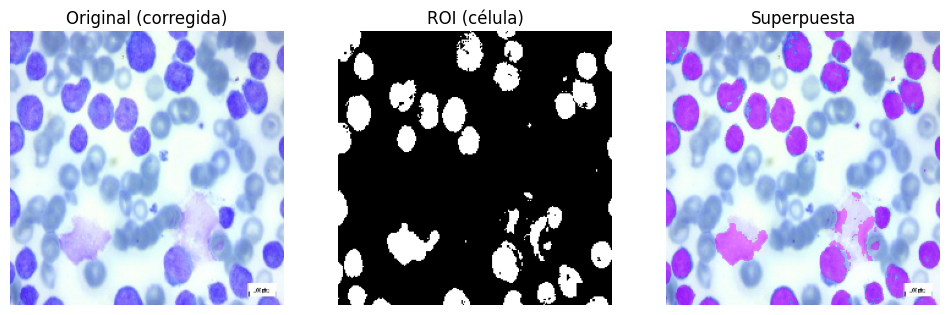

In [3]:
def mascara_celula(ruta_seg):
    """ROI = célula completa, a partir de la segmentación de referencia (fondo negro)."""
    g = cv2.cvtColor(leer(ruta_seg), cv2.COLOR_RGB2GRAY)
    return g > 10

ej = org.sample(1, random_state=3).iloc[0]
rgb, roi = preprocesar(leer(ej.ruta)), mascara_celula(ej.ruta_seg)
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
ax[0].imshow(rgb); ax[0].set_title('Original (corregida)')
ax[1].imshow(roi, cmap='gray'); ax[1].set_title('ROI (célula)')
ax[2].imshow(rgb); ax[2].imshow(np.where(roi, 1, np.nan), cmap='spring', alpha=0.4); ax[2].set_title('Superpuesta')
for a in ax: a.axis('off')
print(f"Fracción de la imagen ocupada por la célula: media = {np.mean([mascara_celula(r).mean() for r in org.ruta_seg.sample(200, random_state=0)]):.1%}")

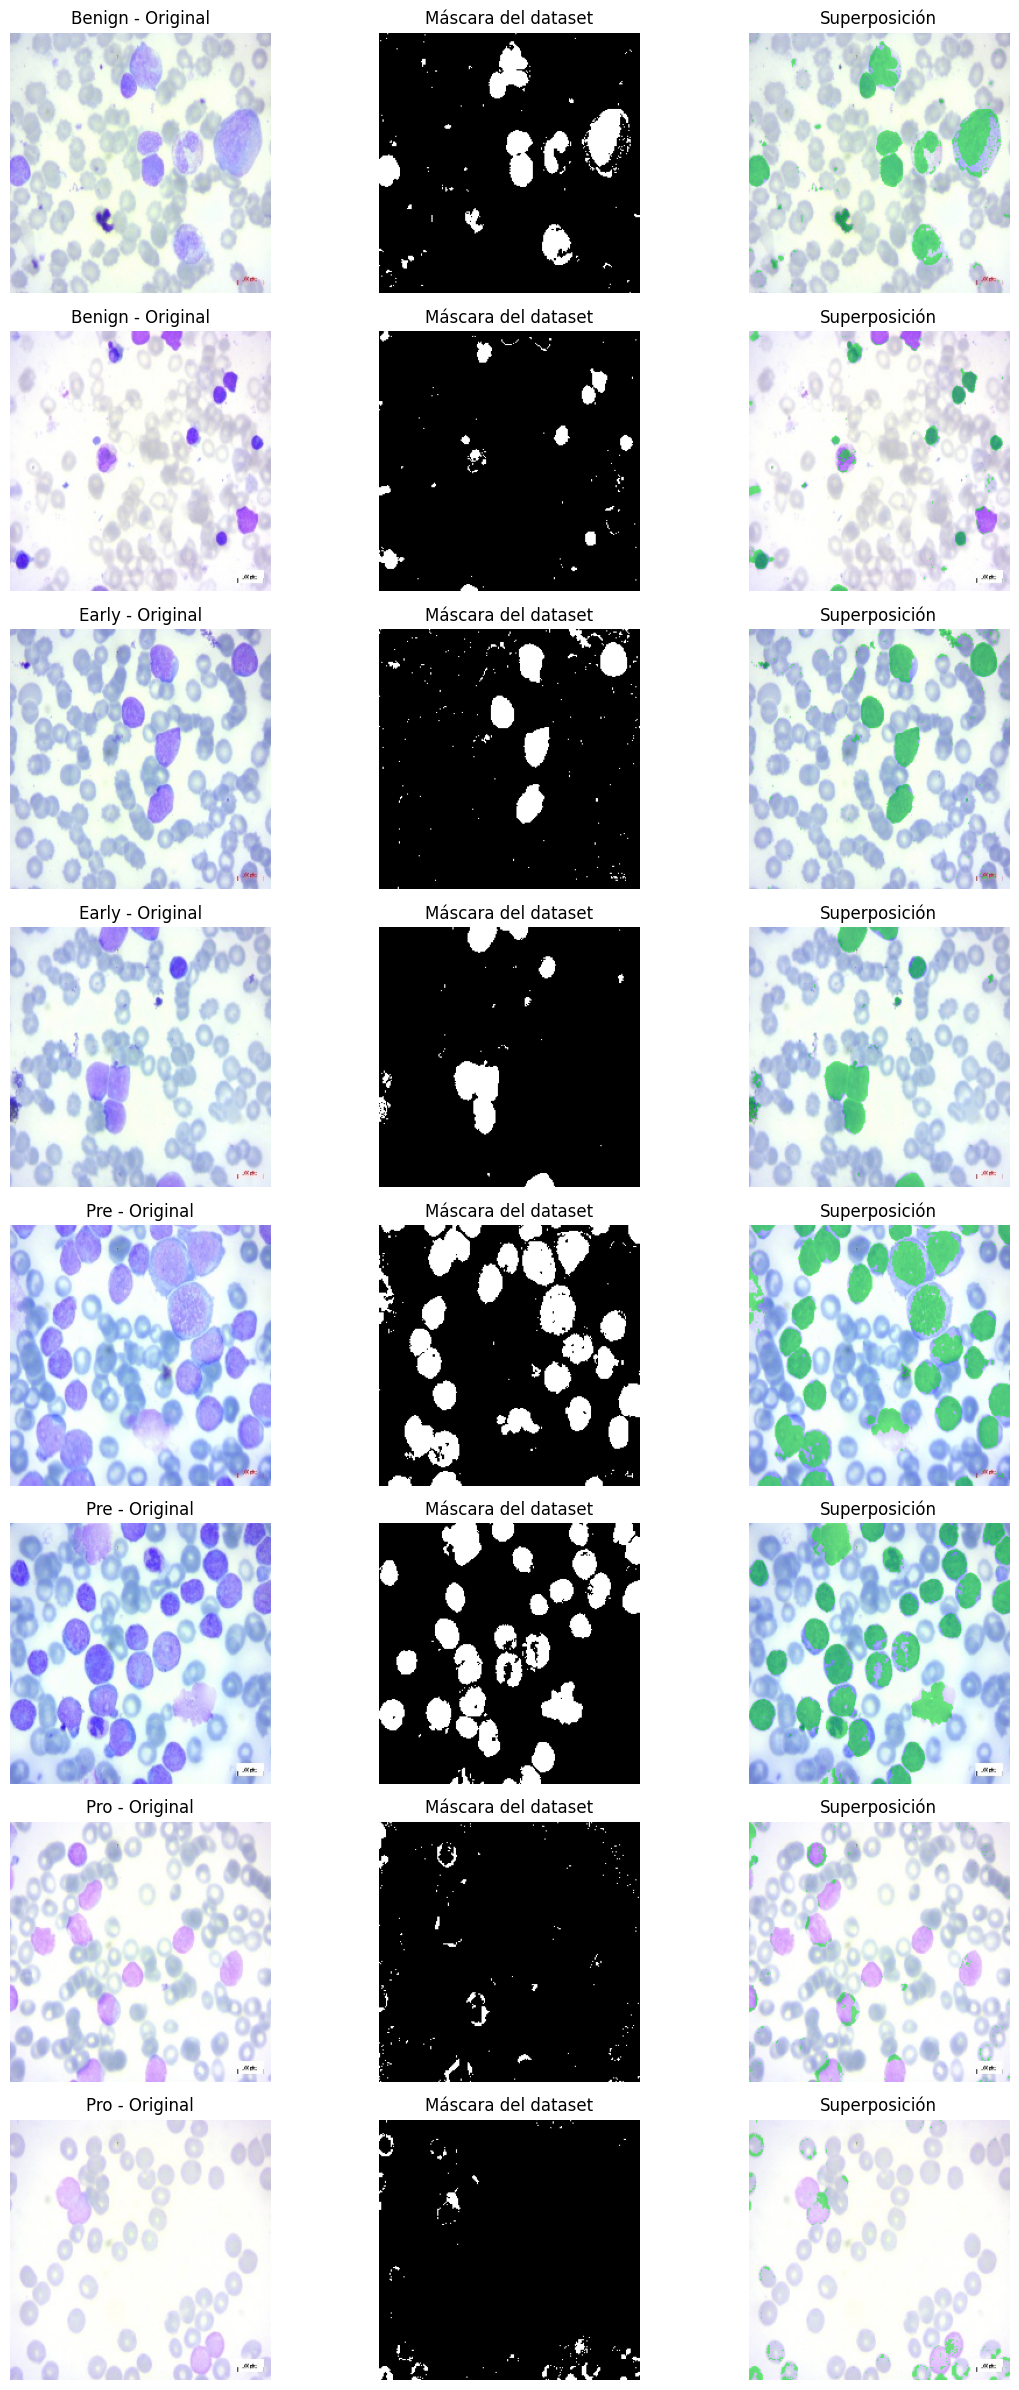

In [4]:

# Verificación visual de las máscaras de referencia
# Dos imágenes de cada subtipo

ejemplos_ref = org.groupby(
    'subtipo', group_keys=False
).sample(n=2, random_state=42)

fig, ax = plt.subplots(
    len(ejemplos_ref), 3,
    figsize=(12, 3 * len(ejemplos_ref))
)

for i, r in enumerate(ejemplos_ref.itertuples()):
    rgb = leer(r.ruta)
    roi = mascara_celula(r.ruta_seg)

    overlay = rgb.copy()
    overlay[roi] = (
        0.5 * rgb[roi] +
        0.5 * np.array([0, 255, 0])
    ).astype(np.uint8)

    ax[i, 0].imshow(rgb)
    ax[i, 0].set_title(f'{r.subtipo} - Original')

    ax[i, 1].imshow(roi, cmap='gray')
    ax[i, 1].set_title('Máscara del dataset')

    ax[i, 2].imshow(overlay)
    ax[i, 2].set_title('Superposición')

    for a in ax[i]:
        a.axis('off')

plt.tight_layout()
plt.show()


## 2. Segmentación del núcleo
### 2.1 Umbral en S (Otsu)
Dentro de la ROI, Otsu busca el umbral de saturación que mejor separa dos poblaciones de píxeles: el núcleo (alta S) del citoplasma/eritrocitos atrapados (baja-media S). Se limpia con apertura morfológica (quita puntos sueltos) y nos quedamos sólo con componentes conexas de área razonable (descarta ruido residual).

In [5]:
AREA_MIN = 25     # px²: componentes más chicas que esto se descartan como ruido

def limpiar(mask, area_min=AREA_MIN):
    """Apertura morfológica + descarte de componentes conexas chicas."""
    m = cv2.morphologyEx(mask.astype(np.uint8), cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    n, etq, stats, _ = cv2.connectedComponentsWithStats(m)
    grandes = [i for i in range(1, n) if stats[i, cv2.CC_STAT_AREA] >= area_min]
    return np.isin(etq, grandes)

def segmentar_hsv(rgb, roi):
    """Núcleo = alta saturación dentro de la ROI (umbral de Otsu calculado sólo con esos píxeles)."""
    s = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)[..., 1]
    umbral, _ = cv2.threshold(s[roi], 0, 255, cv2.THRESH_OTSU)
    return limpiar((s > umbral) & roi)

### 2.2 *k*-means en CIE Lab
Agrupamos los píxeles de la ROI en 2 clusters usando sólo **a\*** y **b\*** (color, sin luminancia: así no se confunde con el problema de iluminación ya corregido en el Módulo 1). El cluster de mayor **croma** $\sqrt{a^{*2}+b^{*2}}$ —color más "puro"/saturado— es el núcleo, consistente con que la tinción lo vuelve violeta intenso.

In [6]:
def segmentar_kmeans(rgb, roi, k=2):
    """k-means en (a*, b*) restringido a la ROI; el cluster de mayor croma es el núcleo."""
    cv2.setRNGSeed(42)    # semilla fija: la inicialización de k-means es aleatoria; así los resultados son reproducibles
    ab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB).astype(np.float32)[..., 1:][roi] - 128
    _, etq, centros = cv2.kmeans(ab, k, None, (cv2.TERM_CRITERIA_EPS, 20, 0.5), 3, cv2.KMEANS_PP_CENTERS)
    nucleo = np.argmax(np.linalg.norm(centros, axis=1))
    mask = np.zeros(roi.shape, bool); mask[roi] = etq.ravel() == nucleo
    return limpiar(mask)

### 2.3 Comparación visual
Mismo ejemplo: máscara por cada método y su solapamiento (verde = sólo HSV, magenta = sólo *k*-means, blanco = coinciden).

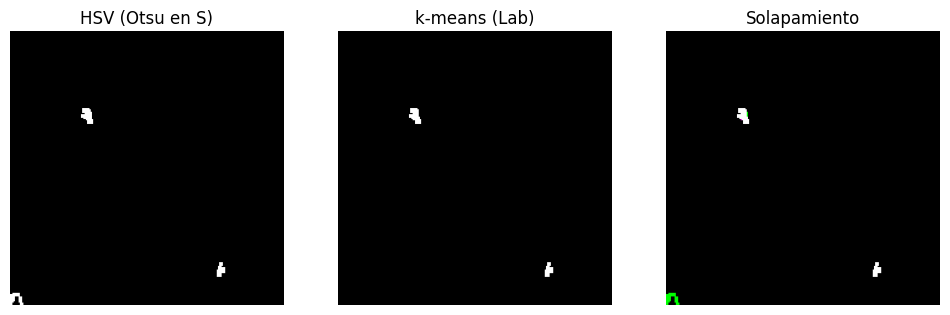

In [7]:
m_hsv, m_km = segmentar_hsv(rgb, roi), segmentar_kmeans(rgb, roi)
solape = np.zeros((*roi.shape, 3), np.uint8)
solape[m_hsv & ~m_km] = (0, 255, 0); solape[m_km & ~m_hsv] = (255, 0, 255); solape[m_hsv & m_km] = (255, 255, 255)
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
ax[0].imshow(m_hsv, cmap='gray'); ax[0].set_title('HSV (Otsu en S)')
ax[1].imshow(m_km, cmap='gray'); ax[1].set_title('k-means (Lab)')
ax[2].imshow(solape); ax[2].set_title('Solapamiento')
for a in ax: a.axis('off')

## 3. Comparación cuantitativa
Sobre una muestra estratificada por subtipo (al no tener máscara de referencia del núcleo, medimos qué tan de acuerdo están los dos métodos entre sí): **Dice**, el **área relativa** del núcleo (núcleo / célula) por método, y el **tiempo** de cómputo.

In [8]:
def dice(a, b):
    """Coeficiente de Dice entre dos máscaras binarias."""
    return 2 * (a & b).sum() / (a.sum() + b.sum() + 1e-9)

muestra = org.groupby('subtipo').sample(40, random_state=0)
filas = []
for r in muestra.itertuples():
    rgb, roi = preprocesar(leer(r.ruta)), mascara_celula(r.ruta_seg)
    m1, m2 = segmentar_hsv(rgb, roi), segmentar_kmeans(rgb, roi)
    filas.append(dict(subtipo=r.subtipo, dice=dice(m1, m2),
                      area_hsv=m1.sum() / roi.sum(), area_kmeans=m2.sum() / roi.sum()))
comp = pd.DataFrame(filas)
comp.groupby('subtipo')[['dice', 'area_hsv', 'area_kmeans']].agg(['mean', 'std']).round(3)

dice        area_hsv        area_kmeans       
          mean    std     mean    std        mean    std
subtipo                                                 
Benign   0.947  0.066    0.413  0.156       0.435  0.149
Early    0.979  0.013    0.623  0.129       0.637  0.130
Pre      0.951  0.071    0.554  0.117       0.574  0.107
Pro      0.631  0.432    0.132  0.139       0.142  0.138

In [9]:
import time
t0 = time.perf_counter(); [segmentar_hsv(rgb, roi) for _ in range(20)]; t_hsv = (time.perf_counter() - t0) / 20
t0 = time.perf_counter(); [segmentar_kmeans(rgb, roi) for _ in range(20)]; t_km = (time.perf_counter() - t0) / 20
print(f"Tiempo por imagen -> HSV: {t_hsv*1000:.1f} ms · k-means: {t_km*1000:.1f} ms")

Tiempo por imagen -> HSV: 0.5 ms · k-means: 1.2 ms


## 4. Conclusiones del Módulo 2
*(Resultados de la corrida sobre el dataset completo — ver el cuadro y los tiempos de arriba.)*

- Concordancia (Dice) entre HSV y *k*-means: **alta y estable en Benign (0.947 ± 0.066), Early (0.979 ± 0.013) y Pre (0.951 ± 0.071); mucho más baja y variable en Pro-B (0.631 ± 0.432)**. Esto confirma la hipótesis: Pro-B es el subtipo con la tinción más pálida (S ≈ 18 en el Módulo 1), y ahí los dos métodos segmentan núcleos distintos con más frecuencia.
- Área relativa del núcleo (fracción de la ROI ocupada): HSV y k-means coinciden de forma consistente en Benign (0.413 vs. 0.435), Early (0.623 vs. 0.637) y Pre (0.554 vs. 0.574); en Pro-B ambos caen y se dispersan mucho más (0.132 vs. 0.142), reflejando la dificultad de detectar un núcleo de bajo contraste.
- Tiempo de cómputo: HSV (≈0.5 ms/imagen) es más rápido que k-means (≈1.2 ms/imagen), unas 2,4 veces más lento este último. Los valores absolutos dependen de la máquina donde se corra; lo que se mantiene es que HSV es más rápido.
- **Decisión:** se elige el método **HSV (Otsu sobre S)**, porque da una concordancia con k-means igual o mejor en los subtipos bien teñidos, es sustancialmente más rápido, y no depende de la inicialización de k-means (aunque la semilla está fija para que los resultados sean reproducibles, el resultado de k-means puede cambiar con la inicialización, lo que es más relevante justo en Pro-B, el caso más inestable).

In [10]:
METODO_SEGMENTACION = 'hsv'    # 'hsv' o 'kmeans' — ver conclusiones

def segmentar(rgb, roi, metodo=METODO_SEGMENTACION):
    """Segmenta el núcleo con el método elegido. Entrada: imagen ya corregida (preprocesar) y ROI (mascara_celula)."""
    return segmentar_hsv(rgb, roi) if metodo == 'hsv' else segmentar_kmeans(rgb, roi)

comp.to_csv('modulo2_comparacion_segmentacion.csv', index=False)

## 5. Segmentación sin la referencia del dataset
*(Agregado a partir del diagnóstico del Módulo 3.)*

La segmentación de referencia que trae el dataset **falla en Pro-B**: en 146 imágenes (18 %) viene vacía y en el resto ocupa sólo ~1 % de la imagen, contra 8–21 % en los demás subtipos (las imágenes de Pro-B están teñidas más pálidas). Como `segmentar()` busca el núcleo *dentro* de esa referencia, en Pro-B casi no detecta núcleos. Además, en los **casos incógnita** de la cátedra no vamos a tener esa referencia.

Por eso probamos segmentar el núcleo **sobre toda la imagen**, sin usar la referencia, con las mismas dos ideas de la sección 2:
1. **Otsu sobre S en toda la imagen**: el fondo (plasma) y los glóbulos rojos tienen baja saturación; los núcleos, alta.
2. ***k*-means en (a\*, b\*) en toda la imagen** con *k* = 3 (núcleo / glóbulos rojos y citoplasma / fondo), tomando como núcleo el cluster de mayor croma.

En ambos casos se limpia igual que antes (apertura + descarte de componentes chicas), se **rellenan los huecos** dentro de los núcleos y se descarta la **esquina inferior derecha**, donde muchas imágenes tienen una marca de agua o barra de escala (Módulo 1).

In [11]:
from scipy import ndimage as ndi

AREA_MIN_NUC = 100        # px²: mismo corte que en el Módulo 3 (debajo es resto/ruido)

def sin_marca(mask):
    # Descarta la esquina inferior derecha (marca de agua / barra de escala).
    m = mask.copy()
    h, w = m.shape
    m[int(h * 0.88):, int(w * 0.75):] = False
    return m

def segmentar_hsv_global(rgb):
    # Otsu sobre S calculado con TODA la imagen (sin ROI de referencia).
    s = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)[..., 1]
    umbral, _ = cv2.threshold(s, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    m = ndi.binary_fill_holes(limpiar(s > umbral, AREA_MIN_NUC))
    return sin_marca(m)

def segmentar_con_ref(rgb, roi):
    # Método de la sección 2, protegido para ROI vacía (pasa en Pro-B): devuelve máscara vacía.
    return segmentar_hsv(rgb, roi) if roi.sum() > 10 else np.zeros(roi.shape, bool)

def segmentar_kmeans_global(rgb, k=3):
    # k-means en (a*, b*) con todos los píxeles; el cluster de mayor croma es el núcleo.
    cv2.setRNGSeed(42)    # semilla fija: la inicialización de k-means es aleatoria; así los resultados son reproducibles
    ab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB).astype(np.float32)[..., 1:].reshape(-1, 2) - 128
    _, etq, centros = cv2.kmeans(ab, k, None, (cv2.TERM_CRITERIA_EPS, 20, 0.5), 3, cv2.KMEANS_PP_CENTERS)
    nucleo = np.argmax(np.linalg.norm(centros, axis=1))
    m = (etq.ravel() == nucleo).reshape(rgb.shape[:2])
    m = ndi.binary_fill_holes(limpiar(m, AREA_MIN_NUC))
    return sin_marca(m)

In [12]:

# Barrido exploratorio de umbrales H y S sobre una muestra chica.
# No es una partición de entrenamiento/prueba: el clasificador y su partición
# 70/30 se definen recién en el Módulo 4. Acá sólo se mira cómo cambian las
# máscaras con los umbrales, para compararlas visualmente con k-means.

# Segmentación HSV por umbrales H y S
def segmentar_hs_global(
    rgb, h_min, h_max, s_min,
    area_min=100
):
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
    h, s = hsv[..., 0], hsv[..., 1]

    mascara = (
        (h >= h_min) &
        (h <= h_max) &
        (s >= s_min)
    )

    mascara = limpiar(mascara, area_min)
    mascara = ndi.binary_fill_holes(mascara)

    return sin_marca(mascara)


# Valores iniciales exploratorios.
# H en OpenCV: 0-179; S: 0-255.
configuraciones_hs = [
    (h_min, h_max, s_min)
    for h_min in [105, 115]
    for h_max in [150, 170]
    for s_min in [60, 90]
]

# Muestra exploratoria: 10 imágenes por subtipo
muestra_exploratoria = org.groupby(
    'subtipo', group_keys=False
).sample(n=10, random_state=42)

resultados_hs = []

for r in muestra_exploratoria.itertuples():
    rgb = preprocesar(leer(r.ruta))

    for h_min, h_max, s_min in configuraciones_hs:
        mascara = segmentar_hs_global(
            rgb, h_min, h_max, s_min
        )

        resultados_hs.append({
            'subtipo': r.subtipo,
            'h_min': h_min,
            'h_max': h_max,
            's_min': s_min,
            'area_segmentada': mascara.mean(),
            'componentes': cv2.connectedComponents(
                mascara.astype(np.uint8)
            )[0] - 1
        })

barrido_hs = pd.DataFrame(resultados_hs)

display(
    barrido_hs.groupby(
        ['h_min', 'h_max', 's_min']
    )[['area_segmentada', 'componentes']]
    .agg(['mean', 'std'])
    .round(3)
)


area_segmentada        componentes        
                             mean    std        mean     std
h_min h_max s_min                                           
105   150   60              0.201  0.203      12.525   8.218
            90              0.093  0.114      11.250  12.840
      170   60              0.201  0.203      12.525   8.218
            90              0.093  0.114      11.250  12.840
115   150   60              0.106  0.093       9.800   6.607
            90              0.068  0.072       8.475   8.363
      170   60              0.106  0.093       9.800   6.607
            90              0.068  0.072       8.475   8.363

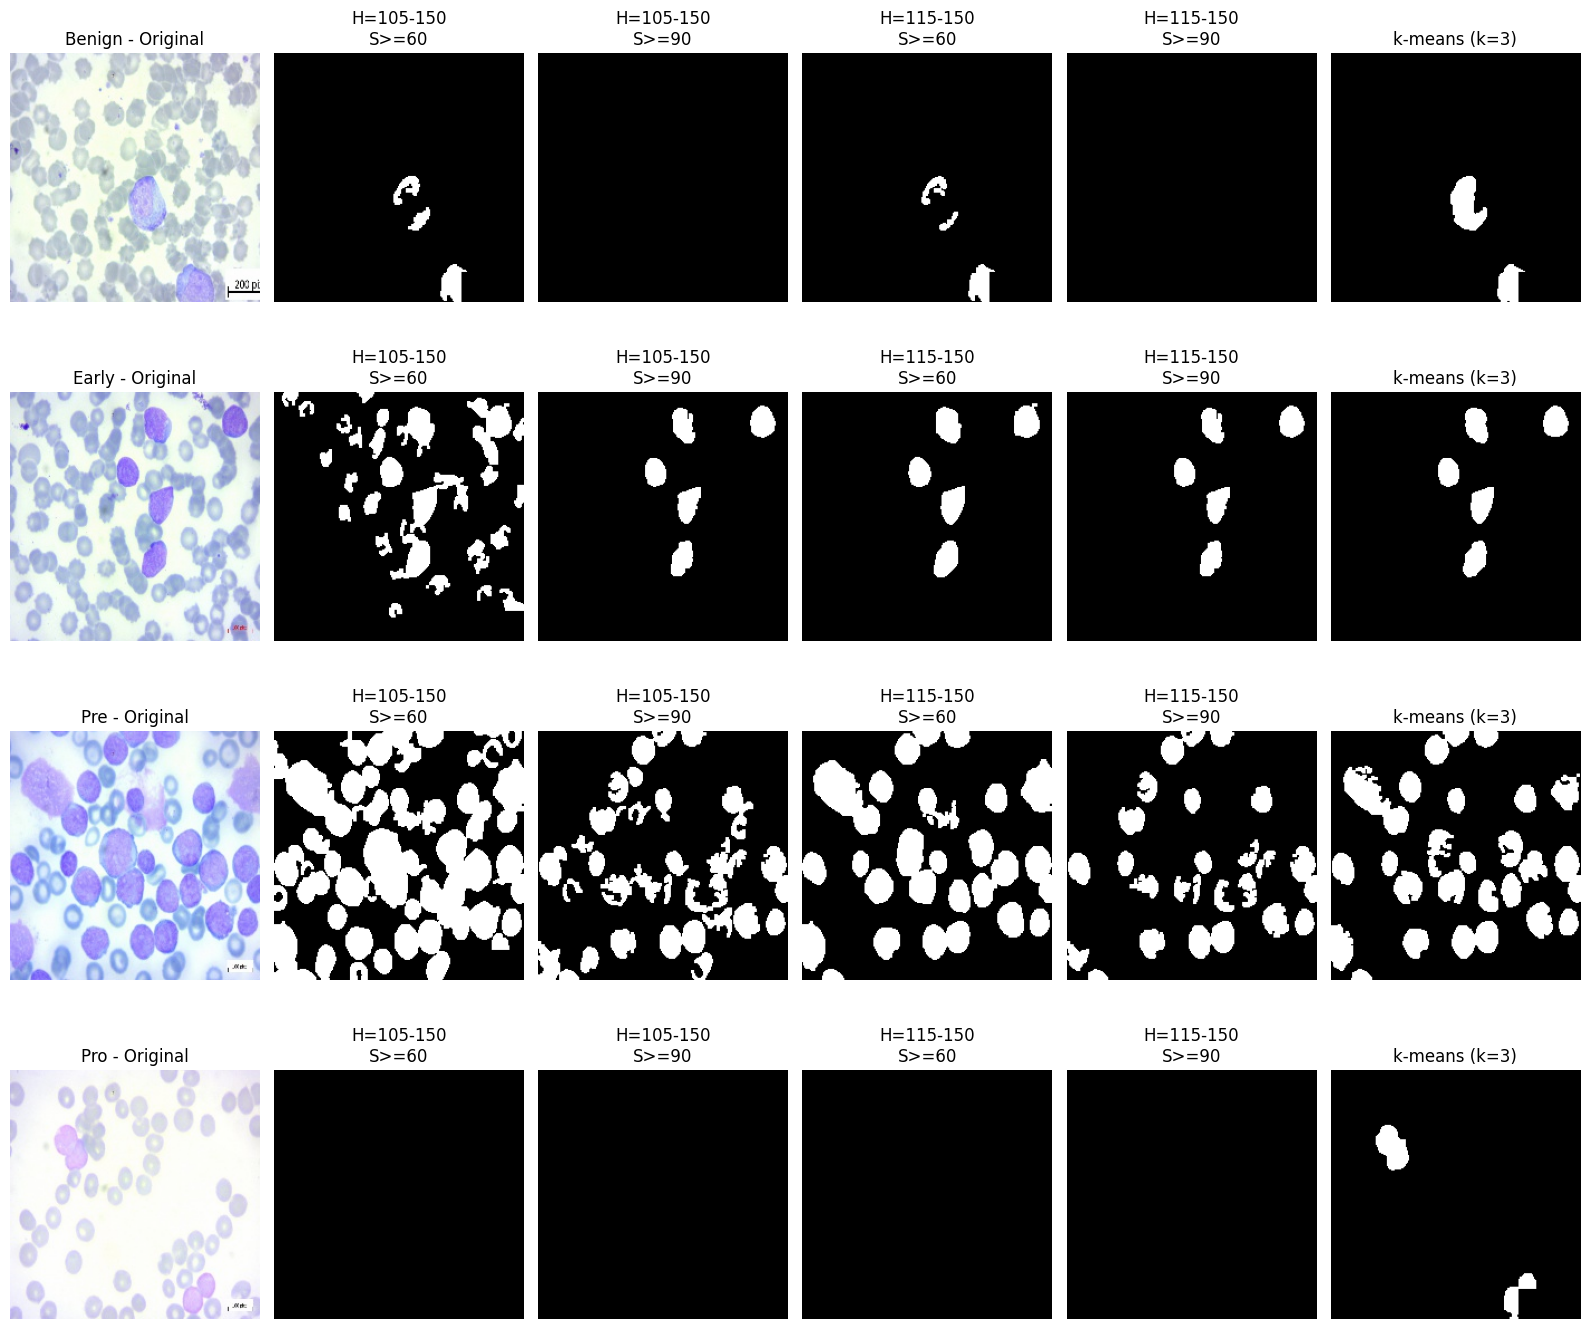

In [13]:

# Comparación visual de HSV H/S y k-means
# Una imagen por subtipo de la muestra exploratoria.

ejemplos = muestra_exploratoria.groupby(
    'subtipo', group_keys=False
).sample(n=1, random_state=42)

configs_hs_visual = [
    (105, 150, 60),
    (105, 150, 90),
    (115, 150, 60),
    (115, 150, 90)
]

fig, ax = plt.subplots(
    len(ejemplos), 6,
    figsize=(16, 3.5 * len(ejemplos))
)

for i, r in enumerate(ejemplos.itertuples()):
    rgb = preprocesar(leer(r.ruta))

    ax[i, 0].imshow(rgb)
    ax[i, 0].set_title(
        f'{r.subtipo} - Original'
    )

    for j, (h_min, h_max, s_min) in enumerate(
        configs_hs_visual, start=1
    ):
        mascara = segmentar_hs_global(
            rgb, h_min, h_max, s_min
        )

        ax[i, j].imshow(mascara, cmap='gray')
        ax[i, j].set_title(
            f'H={h_min}-{h_max}\nS>={s_min}'
        )

    mascara_km = segmentar_kmeans_global(
        rgb, k=3
    )

    ax[i, 5].imshow(mascara_km, cmap='gray')
    ax[i, 5].set_title('k-means (k=3)')

    for a in ax[i]:
        a.axis('off')

plt.tight_layout()
plt.show()


### 5.1 Comparación visual
Dos imágenes de Pro-B (donde falla la referencia) y una de cada otro subtipo. Columnas: original, segmentación con referencia (sección 2, la elegida hasta ahora), y los dos métodos sin referencia.

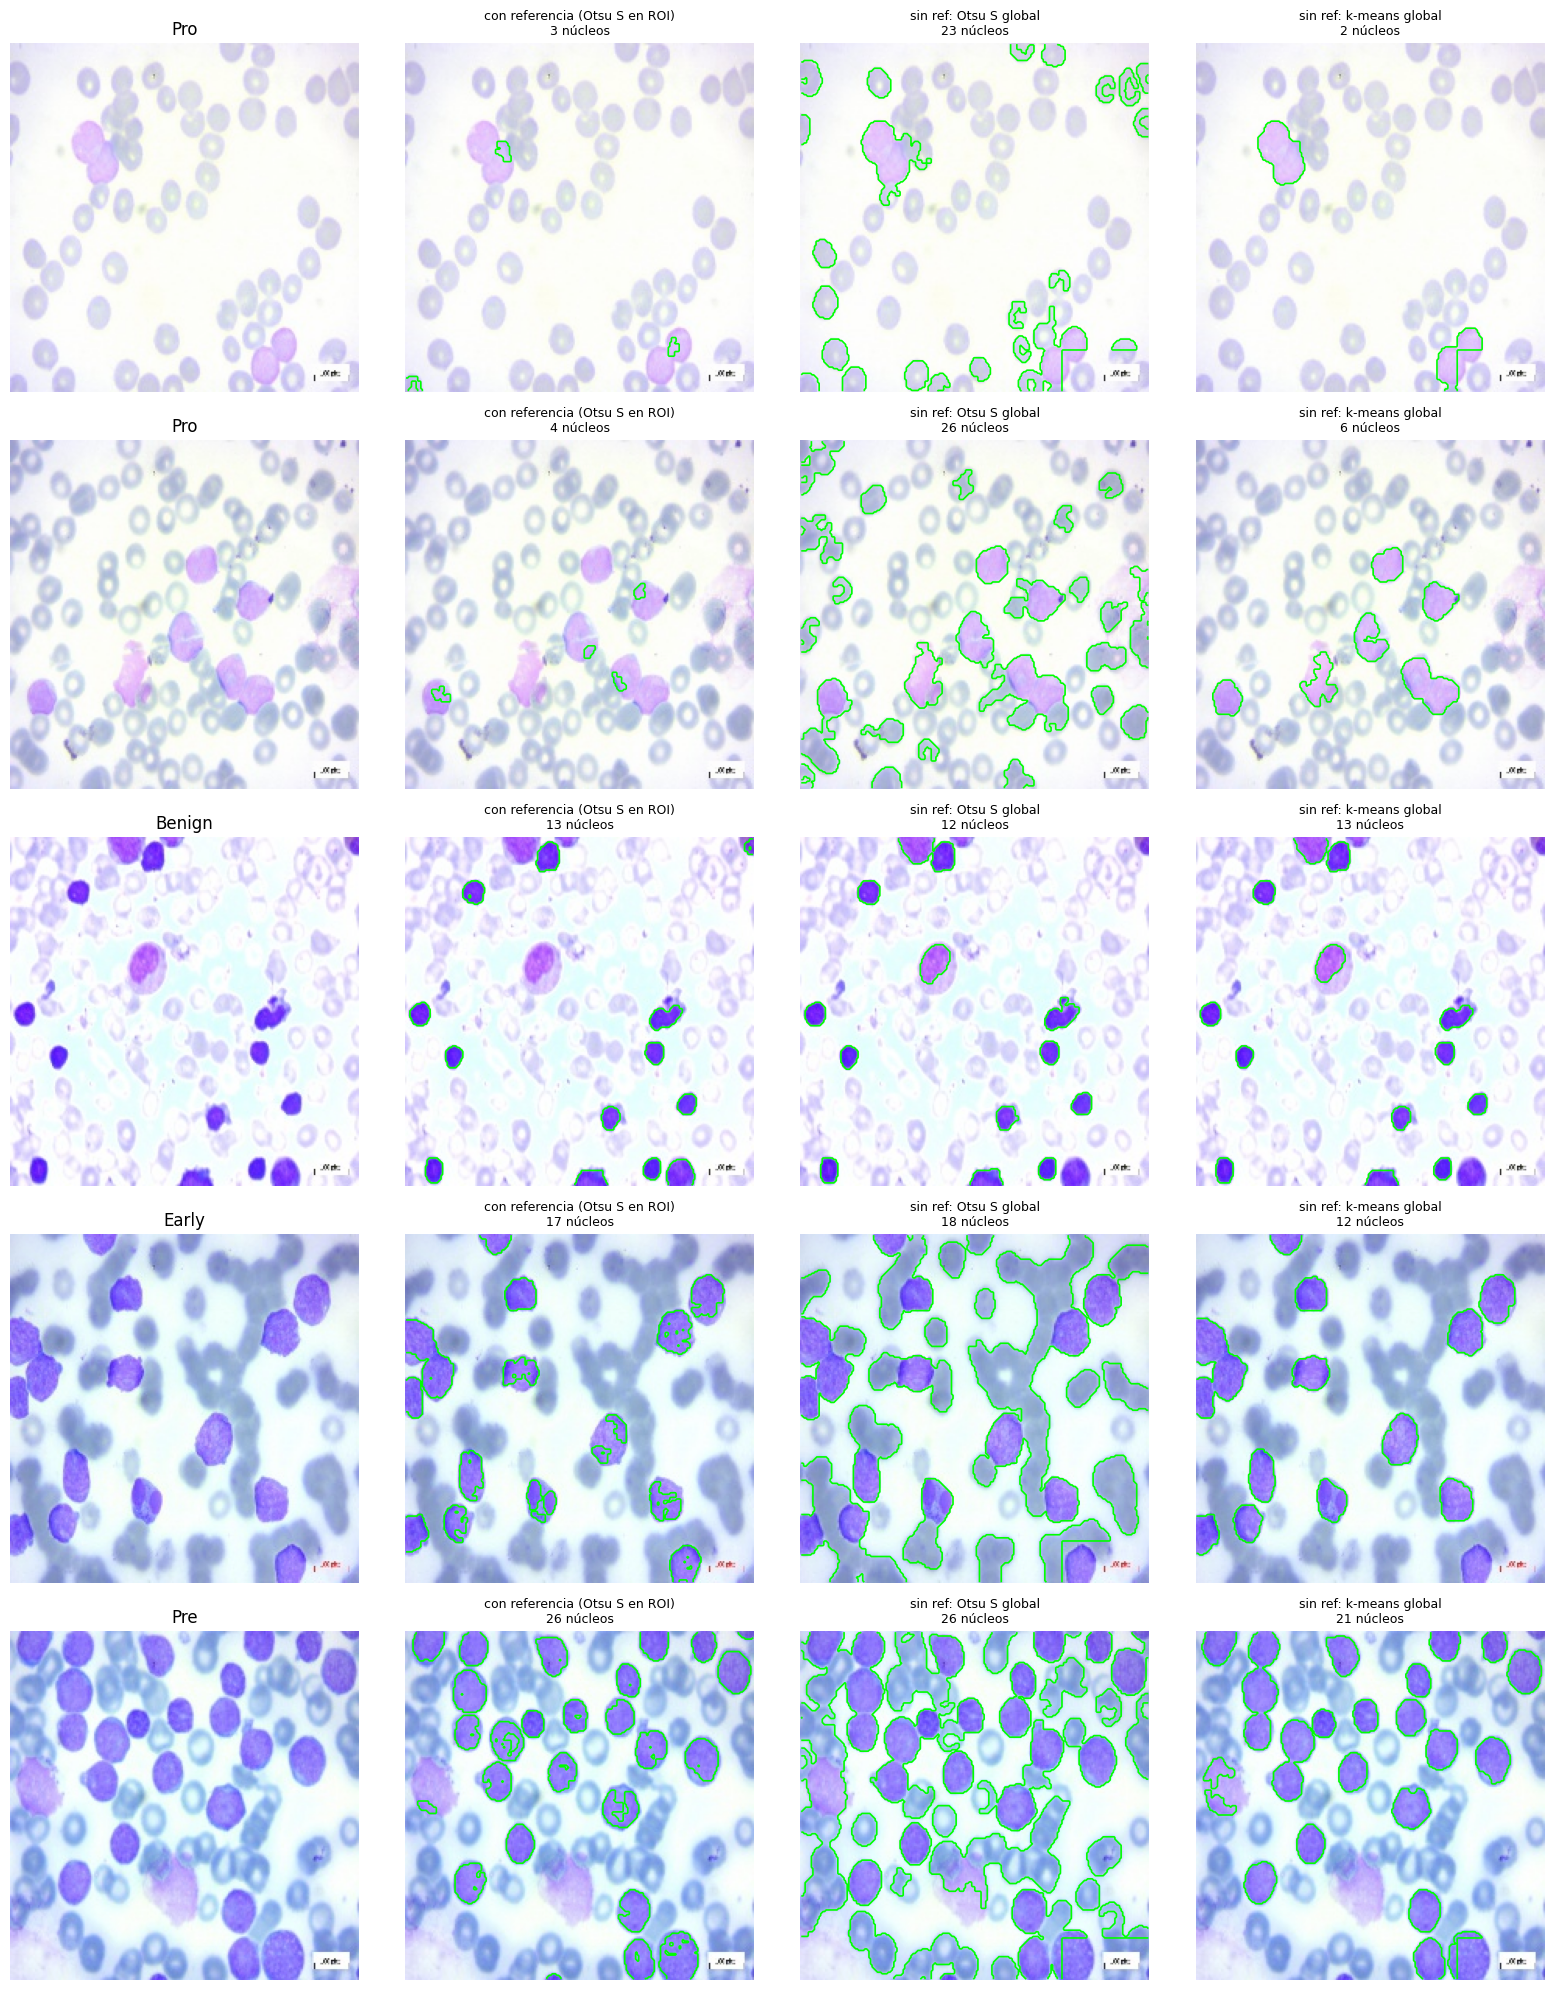

In [14]:
ejemplos = pd.concat([org[org.subtipo.str.contains('Pro')].sample(2, random_state=5),
                      org[~org.subtipo.str.contains('Pro')].groupby('subtipo').sample(1, random_state=5)])
metodos = {'con referencia (Otsu S en ROI)': segmentar_con_ref,
           'sin ref: Otsu S global': lambda rgb, roi: segmentar_hsv_global(rgb),
           'sin ref: k-means global': lambda rgb, roi: segmentar_kmeans_global(rgb)}
fig, ax = plt.subplots(len(ejemplos), 1 + len(metodos), figsize=(4 * (1 + len(metodos)), 4 * len(ejemplos)))
for i, r in enumerate(ejemplos.itertuples()):
    rgb, roi = preprocesar(leer(r.ruta)), mascara_celula(r.ruta_seg)
    ax[i, 0].imshow(rgb); ax[i, 0].set_title(r.subtipo)
    for j, (nombre, f) in enumerate(metodos.items(), start=1):
        m = f(rgb, roi)
        ax[i, j].imshow(rgb); ax[i, j].contour(m, [0.5], colors='lime', linewidths=1.2)
        ax[i, j].set_title(f'{nombre}\n{cv2.connectedComponents(m.astype(np.uint8))[0] - 1} núcleos', fontsize=9)
for a in ax.ravel(): a.axis('off')
plt.tight_layout()

### 5.2 Comparación cuantitativa
En los subtipos Benign, Early y Pre se compara la segmentación global con la obtenida mediante Otsu dentro de la ROI proporcionada por el dataset. Se calculan los coeficientes Dice y Jaccard sobre las regiones comunes a ambas máscaras.

Estas métricas cuantifican la concordancia entre procedimientos, pero no constituyen una validación independiente de la exactitud nuclear, dado que la máscara utilizada como comparación también fue obtenida mediante segmentación automática.

Adicionalmente, se analiza la cantidad de componentes detectados y el porcentaje de imágenes sin regiones segmentadas, complementando estos resultados con inspección visual.

In [15]:
muestra = org.groupby('subtipo').sample(40, random_state=0)
contar = lambda m: cv2.connectedComponents(m.astype(np.uint8))[0] - 1
filas = []


def jaccard(a, b):
    a = np.asarray(a, dtype=bool)
    b = np.asarray(b, dtype=bool)

    union = np.logical_or(a, b).sum()
    inter = np.logical_and(a, b).sum()

    return inter / union if union > 0 else 1.0

for r in muestra.itertuples():
    rgb, roi = preprocesar(leer(r.ruta)), mascara_celula(r.ruta_seg)
    ref = segmentar_con_ref(rgb, roi)
    g_s, g_km = segmentar_hsv_global(rgb), segmentar_kmeans_global(rgb)
    filas.append(dict(subtipo=r.subtipo,
                      dice_S_global=dice(g_s & roi, ref) if roi.any() else np.nan,
                      dice_km_global=dice(g_km & roi, ref) if roi.any() else np.nan,
                      nuc_ref=contar(ref), nuc_S_global=contar(g_s), nuc_km_global=contar(g_km),
                      jaccard_S_global = (jaccard(g_s & roi, ref) if roi.any() else np.nan),
                      jaccard_km_global = (jaccard(g_km & roi, ref) if roi.any() else np.nan),))
comp_global = pd.DataFrame(filas)
resumen = comp_global.groupby('subtipo').agg(
    dice_S_global=('dice_S_global', 'mean'), dice_km_global=('dice_km_global', 'mean'),
    nuc_ref=('nuc_ref', 'median'), nuc_S_global=('nuc_S_global', 'median'), nuc_km_global=('nuc_km_global', 'median'),
    sin_nucleo_ref=('nuc_ref', lambda x: 100 * (x == 0).mean()),
    sin_nucleo_S=('nuc_S_global', lambda x: 100 * (x == 0).mean()),
    sin_nucleo_km=('nuc_km_global', lambda x: 100 * (x == 0).mean()),
    jaccard_S_global=('jaccard_S_global', 'mean'),
    jaccard_km_global=('jaccard_km_global', 'mean'),)
resumen.round(3)

,dice_S_global,dice_km_global,nuc_ref,nuc_S_global,nuc_km_global,sin_nucleo_ref,sin_nucleo_S,sin_nucleo_km,jaccard_S_global,jaccard_km_global
subtipo,,,,,,,,,,
Benign,0.693,0.710,9.5,9.0,8.0,0.0,0.0,0.0,0.566,0.589
Early,0.842,0.909,7.5,12.0,6.0,0.0,0.0,0.0,0.739,0.838
Pre,0.742,0.818,26.0,24.0,21.0,0.0,0.0,0.0,0.601,0.704
Pro,0.220,0.302,1.0,33.0,6.0,30.0,0.0,0.0,0.141,0.208


### 5.3 Conclusión de la sección 5
*(Muestra de 40 imágenes por subtipo.)*

**Visualmente:**
- **Otsu sobre S global sobre-segmenta**: además de los núcleos marca muchos **glóbulos rojos** (en Pro-B detecta 23–33 "núcleos" por imagen que en realidad son eritrocitos). Al calcular el umbral con toda la imagen, el corte queda entre el fondo y *todo lo teñido*, no entre núcleo y el resto.
- ***k*-means global (k = 3)** separa bien núcleo / eritrocitos+citoplasma / fondo: marca los núcleos violetas e ignora los glóbulos rojos, **también en Pro-B**.

**Cuantitativamente:**

| | Benign | Early | Pre | Pro |
|---|---|---|---|---|
| Dice vs. con referencia — Otsu S global | 0,69 | 0,84 | 0,74 | 0,22 |
| Dice vs. con referencia — *k*-means global | **0,71** | **0,91** | **0,82** | 0,30 |
| Mediana de núcleos — con referencia | 9,5 | 7,5 | 26 | **1** |
| Mediana de núcleos — *k*-means global | 8 | 6 | 21 | **6** |
| % imágenes sin núcleo — con referencia | 0 | 0 | 0 | **30 %** |
| % imágenes sin núcleo — *k*-means global | 0 | 0 | 0 | **0 %** |

- En los subtipos Benign, Early y Pre, k-means global presenta mayor concordancia con la segmentación exploratoria dentro de la ROI que Otsu global. En Pro-B, ambos procedimientos presentan menor concordancia, posiblemente debido a las limitaciones de las máscaras proporcionadas por el dataset.

- La inspección visual sugiere que k-means global permite separar mejor las estructuras nucleares de los eritrocitos, por lo que se considera el candidato más adecuado para continuar con la extracción de características. Esta selección ya está validada por las métricas cuantitativas de arriba: Dice y Jaccard más altos que Otsu-S global en los tres subtipos donde la referencia funciona, y recuperación completa de núcleos en Pro-B (0 % de imágenes sin núcleo, contra 30 % con la referencia).

- En el subtipo Pro-B, k-means global detectó componentes en todas las imágenes evaluadas, mientras que la segmentación restringida a la ROI produjo máscaras vacías en el 30 % de los casos. Este resultado sugiere que el método global permite identificar estructuras que no eran detectadas mediante la segmentación con referencia. Sin embargo, la correspondencia de estos componentes con núcleos verdaderos requiere una validación adicional.

**Decisión:** a partir del Módulo 3 se usa ***k*-means global en (a\*, b\*) con k = 3** para segmentar el núcleo. El pipeline queda **independiente de la segmentación de referencia**, así que funciona igual en los casos incógnita.

In [16]:
METODO_SEGMENTACION = 'kmeans_global'    # ver sección 5.3: reemplaza a 'hsv' (sección 4)

def segmentar(rgb, roi=None, metodo=METODO_SEGMENTACION):
    # Segmenta los núcleos. 'kmeans_global' y 'hsv_global' no usan la ROI de referencia.
    if metodo == 'kmeans_global':
        return segmentar_kmeans_global(rgb)
    if metodo == 'hsv_global':
        return segmentar_hsv_global(rgb)
    return segmentar_hsv(rgb, roi) if metodo == 'hsv' else segmentar_kmeans(rgb, roi)